# 27 — Interventional Generator Fingerprints from Context-Utility Response

## Question

The modern-generator intervention revealed heterogeneous response curves across
Qwen2.5, Falcon3, and Llama3.2. That heterogeneity weakens a universal-effect
interpretation, but creates a different possibility:

> **Does a generator's response to controlled self-history restriction contain
> enough stable information to identify the generator on held-out prompts?**

This is black-box **system identification**, not passive authorship detection.
For prompt \(i\), generator \(g\), and scorer \(q\),

\[
\mathbf z_{ig}^{(q)}
=
[\Delta U(32),\Delta U(128),\Delta U(256)].
\]

We classify

\[
g\in\{\text{Qwen2.5},\text{Falcon3},\text{Llama3.2}\}
\]

using leave-one-prompt-out evaluation, so all three realizations of a held-out
RAID prompt remain completely outside training.

The primary population is the intersection of prompts eligible for all three
generators under both frozen Qwen3 scorers. This prevents generator identity
from leaking through eligibility.

### Predeclared feature sets

1. **Length nuisance**: full/cap character lengths and their change.
2. **Qwen3-0.6B response**: \(\Delta U(32,128,256)\).
3. **Qwen3-1.7B response**.
4. **Both scorers**: six response coordinates.
5. **Shape-only 0.6B**: L2-normalized three-coordinate response.
6. **Shape-only both**: normalize each scorer's curve separately.
7. **Length + both scorers**.

Primary classifier: standardized regularized multinomial logistic regression.

Because this experiment was motivated by already-observed heterogeneity, it is
**exploratory**.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
)
from sklearn.model_selection import LeaveOneGroupOut

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

GENERATORS = [
    "Qwen2.5-1.5B-Instruct",
    "Falcon3-3B",
    "Llama3.2-3B",
]

SCORERS = [
    "Qwen3-0.6B",
    "Qwen3-1.7B",
]

N_PERM = 1000
PERM_SEED = 20260901

print("ROOT:", ROOT)
print("Generators:", GENERATORS)
print("Scorers:", SCORERS)


ROOT: ..
Generators: ['Qwen2.5-1.5B-Instruct', 'Falcon3-3B', 'Llama3.2-3B']
Scorers: ['Qwen3-0.6B', 'Qwen3-1.7B']


## 1. Load pair-level intervention measurements

In [2]:
OLD_SCORERS_PATH = RESULTS / "context_intervention_cross_scorer_scores.parquet"
MODERN_SCORERS_PATH = RESULTS / "context_intervention_modern_scorer_scores.parquet"
MODERN_GENERATORS_PATH = RESULTS / "modern_generator_history_intervention_scores.parquet"

for p in [OLD_SCORERS_PATH, MODERN_SCORERS_PATH, MODERN_GENERATORS_PATH]:
    assert p.exists(), f"Missing {p}"

old = pd.read_parquet(OLD_SCORERS_PATH).copy()
modern_s = pd.read_parquet(MODERN_SCORERS_PATH).copy()
modern_g = pd.read_parquet(MODERN_GENERATORS_PATH).copy()

q06 = old[
    (old["generator"] == "Qwen2.5-1.5B-Instruct")
    & (old["scorer"] == "Qwen3")
].copy()
q06["scorer"] = "Qwen3-0.6B"

q17 = modern_s[
    (modern_s["generator"] == "Qwen2.5-1.5B-Instruct")
    & (modern_s["scorer"] == "Qwen3-1.7B")
].copy()

for df in [q06, q17]:
    if "pair_id" in df.columns:
        df.rename(columns={"pair_id": "source_id"}, inplace=True)
    df["source_id"] = df["source_id"].astype(str)

mg = modern_g[
    modern_g["generator"].isin(["Falcon3-3B", "Llama3.2-3B"])
    & modern_g["scorer"].isin(SCORERS)
].copy()
mg["source_id"] = mg["source_id"].astype(str)

measurements = pd.concat([q06, q17, mg], ignore_index=True)

measurements["delta_U_long"] = 0.5 * (
    measurements["delta_U_128"] + measurements["delta_U_256"]
)
measurements["selectivity_long_minus_short"] = (
    measurements["delta_U_long"] - measurements["delta_U_32"]
)

dups = measurements.duplicated(
    ["source_id", "generator", "scorer"],
    keep=False,
)
assert not dups.any(), measurements.loc[dups]

display(
    measurements.groupby(["generator", "scorer"])["eligible"]
    .agg(["sum", "count"])
    .rename(columns={"sum": "eligible_pairs", "count": "total_pairs"})
    .reset_index()
)


,generator,scorer,eligible_pairs,total_pairs
0,Falcon3-3B,Qwen3-0.6B,44,60
1,Falcon3-3B,Qwen3-1.7B,44,60
2,Llama3.2-3B,Qwen3-0.6B,28,60
3,Llama3.2-3B,Qwen3-1.7B,28,60
4,Qwen2.5-1.5B-Instruct,Qwen3-0.6B,60,60
5,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,60,60


## 2. Recover exact generated texts for a length nuisance baseline

In [3]:
GEN_DIR = RESULTS / "modern_generator_history_intervention"

modern_text_frames = []
for gen in ["Falcon3-3B", "Llama3.2-3B"]:
    p = GEN_DIR / f"{gen}_generations.parquet"
    assert p.exists(), p
    z = pd.read_parquet(p).copy()
    z["source_id"] = z["source_id"].astype(str)
    z["generator"] = gen
    modern_text_frames.append(
        z[["source_id", "generator", "condition", "generated_text"]]
    )

modern_texts = pd.concat(modern_text_frames, ignore_index=True)

Q_DIR_CANDIDATES = [
    DATA / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_confirmatory",
]
Q_DIR = next(
    (p for p in Q_DIR_CANDIDATES if (p / "confirmatory_pairs.parquet").exists()),
    None,
)
assert Q_DIR is not None

Q_OLD_CANDIDATES = [
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_intervention" / "context_access_generations.parquet",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_intervention" / "context_access_generations.parquet",
    DATA / "raid_pilot" / "context_access_intervention" / "context_access_generations.parquet",
]
Q_OLD_PATH = next((p for p in Q_OLD_CANDIDATES if p.exists()), None)
assert Q_OLD_PATH is not None

qp = pd.read_parquet(Q_DIR / "confirmatory_pairs.parquet")
q_ids = set(qp["source_id"].astype(str))

qraw = pd.concat(
    [
        pd.read_parquet(Q_DIR / "confirmatory_generations.parquet"),
        pd.read_parquet(Q_OLD_PATH),
    ],
    ignore_index=True,
)
qraw["source_id"] = qraw["source_id"].astype(str)
qraw = qraw[qraw["source_id"].isin(q_ids)].copy()
qraw["_cond"] = qraw["history_cap_label"].astype(str).str.strip().str.lower()
qraw = qraw[qraw["_cond"].isin(["full", "32"])].copy()

conflicts = (
    qraw.groupby(["source_id", "_cond"])["generated_text"]
    .nunique()
    .reset_index(name="n_unique_texts")
)
assert (conflicts["n_unique_texts"] <= 1).all()

qraw = qraw.drop_duplicates(["source_id", "_cond", "generated_text"])
qraw["condition"] = qraw["_cond"].map({"full": "full", "32": "cap32"})
qraw["generator"] = "Qwen2.5-1.5B-Instruct"

q_texts = qraw[
    ["source_id", "generator", "condition", "generated_text"]
].copy()

texts = pd.concat([q_texts, modern_texts], ignore_index=True)

assert not texts.duplicated(
    ["source_id", "generator", "condition"]
).any()

length_wide = texts.assign(
    n_chars=texts["generated_text"].astype(str).str.len()
).pivot(
    index=["source_id", "generator"],
    columns="condition",
    values="n_chars",
).reset_index()

length_wide["len_full_log"] = np.log1p(length_wide["full"])
length_wide["len_cap_log"] = np.log1p(length_wide["cap32"])

delta_chars = length_wide["cap32"] - length_wide["full"]
length_wide["len_delta_signed_log"] = (
    np.sign(delta_chars) * np.log1p(np.abs(delta_chars))
)

display(length_wide.groupby("generator")[["full", "cap32"]].mean())


condition,full,cap32
generator,,
Falcon3-3B,2014.166667,2147.750000
Llama3.2-3B,1994.083333,1974.600000
Qwen2.5-1.5B-Instruct,2176.283333,2160.533333


## 3. Build the balanced common-prompt classification table

In [4]:
required_cells = [(g, s) for g in GENERATORS for s in SCORERS]

elig = measurements.pivot_table(
    index="source_id",
    columns=["generator", "scorer"],
    values="eligible",
    aggfunc="first",
).fillna(False)

for cell in required_cells:
    assert cell in elig.columns, f"Missing cell {cell}"

elig["all_required"] = elig[required_cells].all(axis=1)
common_ids = sorted(elig.index[elig["all_required"]].astype(str))

print("Common prompts:", len(common_ids), "/ 60")

m = measurements[measurements["source_id"].isin(common_ids)].copy()

u_wide = m.pivot(
    index=["source_id", "generator"],
    columns="scorer",
    values=["delta_U_32", "delta_U_128", "delta_U_256"],
)

u_wide.columns = [
    f"{metric}__{scorer}"
    for metric, scorer in u_wide.columns
]
u_wide = u_wide.reset_index()

dataset = u_wide.merge(
    length_wide[
        [
            "source_id",
            "generator",
            "len_full_log",
            "len_cap_log",
            "len_delta_signed_log",
        ]
    ],
    on=["source_id", "generator"],
    how="left",
)

dataset = dataset[
    dataset["source_id"].isin(common_ids)
    & dataset["generator"].isin(GENERATORS)
].copy()

counts = dataset.groupby("source_id")["generator"].nunique()
assert (counts == 3).all()
assert len(dataset) == 3 * len(common_ids)

feature_cols_raw = [
    f"delta_U_{k}__{s}"
    for s in SCORERS
    for k in [32, 128, 256]
]
assert dataset[feature_cols_raw].notna().all().all()

prompt_domain = qp[["source_id", "domain"]].copy()
prompt_domain["source_id"] = prompt_domain["source_id"].astype(str)
prompt_domain = prompt_domain.drop_duplicates()
dataset = dataset.merge(prompt_domain, on="source_id", how="left")

print("Rows:", len(dataset))
display(dataset["generator"].value_counts().to_frame("n"))

print("Common-prompt domains:")
display(
    dataset.drop_duplicates("source_id")["domain"]
    .value_counts()
    .rename("n_prompts")
    .to_frame()
)


Common prompts: 23 / 60
Rows: 69


,n
generator,
Falcon3-3B,23
Llama3.2-3B,23
Qwen2.5-1.5B-Instruct,23


Common-prompt domains:


,n_prompts
domain,
wiki,12
news,11


## 4. Construct raw, normalized-shape, nuisance, and combined feature sets

In [5]:
EPS = 1e-12

def add_shape_features(df, scorer):
    cols = [
        f"delta_U_32__{scorer}",
        f"delta_U_128__{scorer}",
        f"delta_U_256__{scorer}",
    ]
    X = df[cols].to_numpy(dtype=float)
    norm = np.linalg.norm(X, axis=1, keepdims=True)
    shape = X / np.maximum(norm, EPS)

    new_cols = [
        f"shape_U32__{scorer}",
        f"shape_U128__{scorer}",
        f"shape_U256__{scorer}",
    ]
    df[new_cols] = shape
    return new_cols

shape06 = add_shape_features(dataset, "Qwen3-0.6B")
shape17 = add_shape_features(dataset, "Qwen3-1.7B")

u06 = [
    "delta_U_32__Qwen3-0.6B",
    "delta_U_128__Qwen3-0.6B",
    "delta_U_256__Qwen3-0.6B",
]
u17 = [
    "delta_U_32__Qwen3-1.7B",
    "delta_U_128__Qwen3-1.7B",
    "delta_U_256__Qwen3-1.7B",
]
length_cols = [
    "len_full_log",
    "len_cap_log",
    "len_delta_signed_log",
]

FEATURE_SETS = {
    "length_only": length_cols,
    "U_response_0.6B": u06,
    "U_response_1.7B": u17,
    "U_response_both": u06 + u17,
    "U_shape_0.6B": shape06,
    "U_shape_both": shape06 + shape17,
    "length_plus_U_both": length_cols + u06 + u17,
}

for name, cols in FEATURE_SETS.items():
    assert dataset[cols].notna().all().all(), name
    print(f"{name:>20}: {len(cols)} features")


         length_only: 3 features
     U_response_0.6B: 3 features
     U_response_1.7B: 3 features
     U_response_both: 6 features
        U_shape_0.6B: 3 features
        U_shape_both: 6 features
  length_plus_U_both: 9 features


## 5. Leave-one-prompt-out generator identification

Chance accuracy is \(1/3\). Standardization and classifier fitting occur only
inside each training fold.


In [6]:
LABELS = GENERATORS

base_classifier = Pipeline([
    ("scale", StandardScaler()),
    (
        "clf",
        LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            C=1.0,
        ),
    ),
])

def leave_one_prompt_out_predictions(df, features, label_col="generator"):
    X = df[features].to_numpy(dtype=float)
    y = df[label_col].to_numpy()
    groups = df["source_id"].to_numpy()

    logo = LeaveOneGroupOut()
    pred = np.empty(len(df), dtype=object)

    for train_idx, test_idx in logo.split(X, y, groups):
        model = clone(base_classifier)
        model.fit(X[train_idx], y[train_idx])
        pred[test_idx] = model.predict(X[test_idx])

    out = df[["source_id", "generator"]].copy()
    out["predicted"] = pred
    out["correct"] = out["generator"] == out["predicted"]
    return out

def summarize_predictions(pred):
    y = pred["generator"]
    yhat = pred["predicted"]
    return {
        "accuracy": accuracy_score(y, yhat),
        "balanced_accuracy": balanced_accuracy_score(y, yhat),
        "macro_f1": f1_score(y, yhat, average="macro"),
    }

prediction_tables = {}
rows = []

for feature_name, features in FEATURE_SETS.items():
    pred = leave_one_prompt_out_predictions(dataset, features)
    prediction_tables[feature_name] = pred
    stats = summarize_predictions(pred)
    rows.append({
        "feature_set": feature_name,
        "n_prompts": len(common_ids),
        "n_rows": len(pred),
        "n_features": len(features),
        **stats,
    })

cv_results = pd.DataFrame(rows)
display(cv_results.sort_values("balanced_accuracy", ascending=False))


,feature_set,n_prompts,n_rows,n_features,accuracy,balanced_accuracy,macro_f1
0,length_only,23,69,3,0.521739,0.521739,0.521135
6,length_plus_U_both,23,69,9,0.492754,0.492754,0.491952
1,U_response_0.6B,23,69,3,0.391304,0.391304,0.389468
4,U_shape_0.6B,23,69,3,0.376812,0.376812,0.377576
2,U_response_1.7B,23,69,3,0.362319,0.362319,0.359182
3,U_response_both,23,69,6,0.347826,0.347826,0.347386
5,U_shape_both,23,69,6,0.304348,0.304348,0.304752


## 6. Within-prompt permutation test

Generator labels are shuffled independently within each prompt, preserving
exactly one example per class per source ID.

\[
p_{\rm perm}
=
\frac{1+\#\{\mathrm{acc}_{\pi}\ge\mathrm{acc}_{\rm obs}\}}
{1+B}.
\]


In [7]:
from joblib import Parallel, delayed
import os

# ============================================================
# FAST STAGED WITHIN-PROMPT PERMUTATION TEST
# ============================================================

N_STAGE1 = 250
N_STAGE2 = 2000
SEED = 20260901

# Leave one core free so the laptop remains usable.
N_JOBS = max(1, (os.cpu_count() or 2) - 1)

print("parallel jobs:", N_JOBS)


# ------------------------------------------------------------
# Precompute group splits once.
# ------------------------------------------------------------

groups = dataset["source_id"].to_numpy()
logo = LeaveOneGroupOut()

CV_SPLITS = list(
    logo.split(
        np.zeros(len(dataset)),
        dataset["generator"].to_numpy(),
        groups,
    )
)

print("CV folds:", len(CV_SPLITS))


def cv_balanced_accuracy_fast(X, y):
    pred = np.empty(len(y), dtype=object)

    for train_idx, test_idx in CV_SPLITS:

        model = clone(base_classifier)

        model.fit(
            X[train_idx],
            y[train_idx],
        )

        pred[test_idx] = model.predict(
            X[test_idx]
        )

    return balanced_accuracy_score(
        y,
        pred,
    )


# ------------------------------------------------------------
# Represent within-prompt membership once.
# ------------------------------------------------------------

prompt_indices = [
    np.asarray(idx, dtype=int)
    for idx in dataset.groupby("source_id").indices.values()
]

true_y = dataset["generator"].to_numpy()


def make_permuted_labels(seed):
    rng = np.random.default_rng(seed)

    y = true_y.copy()

    for idx in prompt_indices:
        y[idx] = rng.permutation(
            y[idx]
        )

    return y


def one_permutation(X, seed):
    y_perm = make_permuted_labels(seed)

    return cv_balanced_accuracy_fast(
        X,
        y_perm,
    )


# Cache X matrices.
X_CACHE = {
    name: dataset[features].to_numpy(dtype=float)
    for name, features in FEATURE_SETS.items()
}


def run_null(feature_name, seeds):
    X = X_CACHE[feature_name]

    vals = Parallel(
        n_jobs=N_JOBS,
        prefer="threads",
    )(
        delayed(one_permutation)(
            X,
            int(seed),
        )
        for seed in seeds
    )

    return np.asarray(
        vals,
        dtype=float,
    )


# ============================================================
# STAGE 1 — 250 permutations for everything
# ============================================================

master_rng = np.random.default_rng(SEED)

stage1_rows = []
stage1_nulls = {}

for feature_name in FEATURE_SETS:

    print("\nStage 1:", feature_name)

    seeds = master_rng.integers(
        0,
        2**32 - 1,
        size=N_STAGE1,
        dtype=np.uint32,
    )

    null = run_null(
        feature_name,
        seeds,
    )

    stage1_nulls[feature_name] = null

    observed = float(
        cv_results.loc[
            cv_results["feature_set"]
            == feature_name,
            "balanced_accuracy",
        ].iloc[0]
    )

    p = (
        1
        + np.sum(null >= observed)
    ) / (
        len(null) + 1
    )

    stage1_rows.append({
        "feature_set": feature_name,
        "observed_balanced_accuracy": observed,
        "null_mean": null.mean(),
        "null_sd": null.std(ddof=1),
        "p_stage1": p,
        "n_perm": len(null),
    })


stage1 = pd.DataFrame(
    stage1_rows
).sort_values("p_stage1")

display(stage1)


# ============================================================
# STAGE 2 — only potentially interesting feature sets
# ============================================================

PROMISING = stage1.loc[
    stage1["p_stage1"] < 0.10,
    "feature_set",
].tolist()

print(
    "\nFeature sets continuing to Stage 2:",
    PROMISING,
)


final_rows = []
perm_distributions = {}

for feature_name in FEATURE_SETS:

    null = stage1_nulls[
        feature_name
    ]

    if feature_name in PROMISING:

        n_extra = (
            N_STAGE2
            - len(null)
        )

        print(
            f"\nExtending {feature_name}: "
            f"{len(null)} -> {N_STAGE2}"
        )

        extra_seeds = master_rng.integers(
            0,
            2**32 - 1,
            size=n_extra,
            dtype=np.uint32,
        )

        extra = run_null(
            feature_name,
            extra_seeds,
        )

        null = np.concatenate(
            [null, extra]
        )

    perm_distributions[
        feature_name
    ] = null

    observed = float(
        cv_results.loc[
            cv_results["feature_set"]
            == feature_name,
            "balanced_accuracy",
        ].iloc[0]
    )

    p_perm = (
        1
        + np.sum(null >= observed)
    ) / (
        len(null) + 1
    )

    final_rows.append({
        "feature_set": feature_name,
        "observed_balanced_accuracy": observed,
        "null_mean": null.mean(),
        "null_sd": null.std(ddof=1),
        "p_perm": p_perm,
        "n_permutations": len(null),
    })


perm_results = pd.DataFrame(
    final_rows
).sort_values("p_perm")

print("\n=== FINAL PERMUTATION RESULTS ===")
display(perm_results)

parallel jobs: 21
CV folds: 23

Stage 1: length_only

Stage 1: U_response_0.6B

Stage 1: U_response_1.7B

Stage 1: U_response_both

Stage 1: U_shape_0.6B

Stage 1: U_shape_both

Stage 1: length_plus_U_both


,feature_set,observed_balanced_accuracy,null_mean,null_sd,p_stage1,n_perm
0,length_only,0.521739,0.330145,0.067159,0.003984,250
6,length_plus_U_both,0.492754,0.328696,0.064985,0.011952,250
1,U_response_0.6B,0.391304,0.338261,0.064514,0.258964,250
2,U_response_1.7B,0.362319,0.325797,0.062605,0.322709,250
4,U_shape_0.6B,0.376812,0.336522,0.066095,0.330677,250
3,U_response_both,0.347826,0.326783,0.065666,0.410359,250
5,U_shape_both,0.304348,0.331246,0.064728,0.657371,250



Feature sets continuing to Stage 2: ['length_only', 'length_plus_U_both']

Extending length_only: 250 -> 2000

Extending length_plus_U_both: 250 -> 2000

=== FINAL PERMUTATION RESULTS ===


,feature_set,observed_balanced_accuracy,null_mean,null_sd,p_perm,n_permutations
0,length_only,0.521739,0.330978,0.073856,0.001999,2000
6,length_plus_U_both,0.492754,0.332913,0.066660,0.009495,2000
1,U_response_0.6B,0.391304,0.338261,0.064514,0.258964,250
2,U_response_1.7B,0.362319,0.325797,0.062605,0.322709,250
4,U_shape_0.6B,0.376812,0.336522,0.066095,0.330677,250
3,U_response_both,0.347826,0.326783,0.065666,0.410359,250
5,U_shape_both,0.304348,0.331246,0.064728,0.657371,250


## 7. Confusion matrices and per-generator recall

In [8]:
recall_rows = []

for feature_name, pred in prediction_tables.items():
    cm = confusion_matrix(
        pred["generator"],
        pred["predicted"],
        labels=LABELS,
    )

    print("\n", "=" * 70)
    print(feature_name)
    display(
        pd.DataFrame(
            cm,
            index=[f"true:{x}" for x in LABELS],
            columns=[f"pred:{x}" for x in LABELS],
        )
    )

    recalls = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)

    for label, recall in zip(LABELS, recalls):
        recall_rows.append({
            "feature_set": feature_name,
            "generator": label,
            "recall": float(recall),
        })

recall_df = pd.DataFrame(recall_rows)

print("\nPer-generator recalls:")
display(
    recall_df.pivot(
        index="feature_set",
        columns="generator",
        values="recall",
    )
)



length_only


,pred:Qwen2.5-1.5B-Instruct,pred:Falcon3-3B,pred:Llama3.2-3B
true:Qwen2.5-1.5B-Instruct,11,6,6
true:Falcon3-3B,5,13,5
true:Llama3.2-3B,5,6,12



U_response_0.6B


,pred:Qwen2.5-1.5B-Instruct,pred:Falcon3-3B,pred:Llama3.2-3B
true:Qwen2.5-1.5B-Instruct,10,7,6
true:Falcon3-3B,9,7,7
true:Llama3.2-3B,9,4,10



U_response_1.7B


...

,pred:Qwen2.5-1.5B-Instruct,pred:Falcon3-3B,pred:Llama3.2-3B
true:Qwen2.5-1.5B-Instruct,8,9,6
true:Falcon3-3B,8,6,9
true:Llama3.2-3B,7,9,7



length_plus_U_both


,pred:Qwen2.5-1.5B-Instruct,pred:Falcon3-3B,pred:Llama3.2-3B
true:Qwen2.5-1.5B-Instruct,9,8,6
true:Falcon3-3B,7,12,4
true:Llama3.2-3B,6,4,13



Per-generator recalls:


generator,Falcon3-3B,Llama3.2-3B,Qwen2.5-1.5B-Instruct
feature_set,,,
U_response_0.6B,0.304348,0.434783,0.434783
U_response_1.7B,0.260870,0.478261,0.347826
U_response_both,0.304348,0.347826,0.391304
U_shape_0.6B,0.304348,0.434783,0.391304
U_shape_both,0.260870,0.304348,0.347826
length_only,0.565217,0.521739,0.478261
length_plus_U_both,0.521739,0.565217,0.391304


## 8. Does context-utility response add information beyond length?

We compare held-out prompt-level correctness between selected feature sets. Each
prompt contributes a correctness fraction over its three generators.


In [9]:
def prompt_correct_fraction(pred):
    return (
        pred.groupby("source_id")["correct"]
        .mean()
        .rename("correct_fraction")
    )

prompt_scores = {
    name: prompt_correct_fraction(pred)
    for name, pred in prediction_tables.items()
}

def paired_prompt_bootstrap_difference(a, b, n_boot=10_000, seed=20260901):
    x = pd.concat([a.rename("a"), b.rename("b")], axis=1).dropna()
    d = (x["a"] - x["b"]).to_numpy(dtype=float)

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for i in range(n_boot):
        idx = rng.integers(0, len(d), size=len(d))
        boot[i] = d[idx].mean()

    return {
        "n_prompts": len(d),
        "mean_difference": float(d.mean()),
        "ci_low": float(np.quantile(boot, .025)),
        "ci_high": float(np.quantile(boot, .975)),
    }

comparisons = [
    ("U_response_both", "length_only"),
    ("length_plus_U_both", "length_only"),
    ("U_shape_both", "U_response_both"),
    ("U_response_1.7B", "U_response_0.6B"),
]

comparison_rows = []

for a, b in comparisons:
    comparison_rows.append({
        "feature_set_A": a,
        "feature_set_B": b,
        **paired_prompt_bootstrap_difference(
            prompt_scores[a],
            prompt_scores[b],
        ),
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)


,feature_set_A,feature_set_B,n_prompts,mean_difference,ci_low,ci_high
0,U_response_both,length_only,23,-0.173913,-0.333333,4.827057e-18
1,length_plus_U_both,length_only,23,-0.028986,-0.115942,5.797101e-02
2,U_shape_both,U_response_both,23,-0.043478,-0.159420,7.246377e-02
3,U_response_1.7B,U_response_0.6B,23,-0.028986,-0.173913,1.014493e-01


## 9. Main visualization

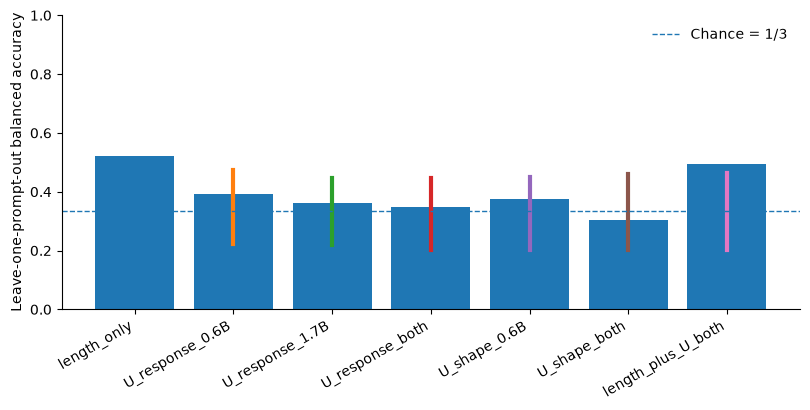

saved: ../figures/interventional_generator_fingerprint.pdf
saved: ../figures/interventional_generator_fingerprint.png


In [10]:
plot_order = [
    "length_only",
    "U_response_0.6B",
    "U_response_1.7B",
    "U_response_both",
    "U_shape_0.6B",
    "U_shape_both",
    "length_plus_U_both",
]

obs = (
    cv_results.set_index("feature_set")
    .loc[plot_order, "balanced_accuracy"]
)

null_lo = np.array([
    np.quantile(perm_distributions[x], .025)
    for x in plot_order
])
null_hi = np.array([
    np.quantile(perm_distributions[x], .975)
    for x in plot_order
])

x = np.arange(len(plot_order))

fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.bar(x, obs.to_numpy())

for i in range(len(x)):
    ax.plot(
        [x[i], x[i]],
        [null_lo[i], null_hi[i]],
        linewidth=3,
    )

ax.axhline(1/3, linestyle="--", linewidth=1, label="Chance = 1/3")
ax.set_xticks(x)
ax.set_xticklabels(plot_order, rotation=30, ha="right")
ax.set_ylabel("Leave-one-prompt-out balanced accuracy")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

FIG_PDF = FIGURES / "interventional_generator_fingerprint.pdf"
FIG_PNG = FIGURES / "interventional_generator_fingerprint.png"

fig.savefig(FIG_PDF, bbox_inches="tight")
fig.savefig(FIG_PNG, dpi=250, bbox_inches="tight")
plt.show()

print("saved:", FIG_PDF)
print("saved:", FIG_PNG)


## 10. Save outputs

In [11]:
OUT_DIR = RESULTS / "interventional_generator_fingerprint"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = OUT_DIR / "common_prompt_features.parquet"
CV_PATH = OUT_DIR / "cv_results.csv"
PERM_PATH = OUT_DIR / "permutation_results.csv"
RECALL_PATH = OUT_DIR / "per_generator_recall.csv"
COMPARE_PATH = OUT_DIR / "feature_set_comparisons.csv"

dataset.to_parquet(DATASET_PATH, index=False)
cv_results.to_csv(CV_PATH, index=False)
perm_results.to_csv(PERM_PATH, index=False)
recall_df.to_csv(RECALL_PATH, index=False)
comparison_df.to_csv(COMPARE_PATH, index=False)

for name, pred in prediction_tables.items():
    pred.to_csv(OUT_DIR / f"predictions_{name}.csv", index=False)

for name, null in perm_distributions.items():
    pd.DataFrame({"balanced_accuracy": null}).to_csv(
        OUT_DIR / f"null_{name}.csv",
        index=False,
    )

print("saved:")
for p in [
    DATASET_PATH,
    CV_PATH,
    PERM_PATH,
    RECALL_PATH,
    COMPARE_PATH,
    FIG_PDF,
    FIG_PNG,
]:
    print(" ", p)


saved:
  ../results/interventional_generator_fingerprint/common_prompt_features.parquet
  ../results/interventional_generator_fingerprint/cv_results.csv
  ../results/interventional_generator_fingerprint/permutation_results.csv
  ../results/interventional_generator_fingerprint/per_generator_recall.csv
  ../results/interventional_generator_fingerprint/feature_set_comparisons.csv
  ../figures/interventional_generator_fingerprint.pdf
  ../figures/interventional_generator_fingerprint.png


## 11. Interpretation gate

### Response features classify above chance and beat length

Safe interpretation:

> Controlled history-response curves contain generator-specific behavioral
> information that transfers to unseen prompts and is not reducible to simple
> output-length changes.

This supports an **interventional behavioral fingerprint** interpretation.

### Raw response works but shape-only collapses

Identity is carried mainly by response amplitude rather than a distinctive
trajectory across context scales.

### Shape-only remains predictive

Generator identity is reflected in the relative context-scale trajectory as
well as intervention magnitude.

### Length-only performs similarly to U

Much of the apparent generator separation is explainable by verbosity or
termination changes rather than a distinct context-utility fingerprint.

### Everything is near chance

Mean heterogeneity is not stable enough at the individual prompt level to
support generator identification.

## Claim boundary

Even a successful result identifies generators from a **controlled response
experiment**. It does not imply reliable attribution from one naturally
occurring document, nor uniquely identify architecture, tokenizer, training
data, or post-training method.
